In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/retail_campaign.csv")
df.head()

,customer_id,recency,history,used_discount,used_bogo,is_referral,zip_code_Rural,zip_code_Surburban,zip_code_Urban,channel_Multichannel,channel_Phone,channel_Web,discount,revenue
0,2,6,329.08,1,1,1,1,0,0,0,0,1,0,0.0
1,4,9,675.83,1,0,1,1,0,0,0,0,1,1,0.0
2,9,9,675.07,1,1,1,1,0,0,0,1,0,1,0.0
3,14,2,101.64,0,1,0,0,0,1,0,0,1,1,25.0
4,15,4,241.42,0,1,1,1,0,0,1,0,0,0,0.0


In [3]:
%pip install econml lightgbm

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.3 MB 1.5 MB/s eta 0:00:02
   ------------------ --------------------- 1.0/2.3 MB 1.7 MB/s eta 0:00:01
   ------------------------------- -------- 1.8/2.3 MB 2.0 MB/s eta 0:00:01
   ------------------------------------ --- 2.1/2.3 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 2.3/2.3 MB 1.8 MB/s  0:00:01
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.9 MB/s  0:00:00
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 3.9 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22

In [9]:
import importlib
import src.evaluation as ev
importlib.reload(ev)
ev.decile_check(df, ite_lin)

,group,n,mean_predicted_ite,observed_effect,std_error
0,Top 1/5,8523,2.628266,2.665668,0.218593
1,Top 2/5,8522,1.836339,1.584656,0.194952
2,Top 3/5,8523,1.740601,1.987296,0.183974
3,Top 4/5,8522,1.651760,1.644273,0.174230
4,Top 5/5,8523,1.521955,1.661551,0.164487


In [10]:
from src.double_ml import fit_linear_dml, fit_forest_dml, predict_ite, save_ite_scores
from src.evaluation import decile_check

lin = fit_linear_dml(df)
ite_lin = predict_ite(lin, df)
decile_check(df, ite_lin)

c:\Users\DELL\Desktop\Python Course\venv\Lib\site-packages\econml\sklearn_extensions\linear_model.py:1946: UserWarning: Co-variance matrix is underdetermined. Inference will be invalid!
  warnings.warn("Co-variance matrix is underdetermined. Inference will be invalid!")


,group,n,mean_predicted_ite,observed_effect,std_error
0,Top 1/5,8523,2.628266,2.665668,0.218593
1,Top 2/5,8522,1.836339,1.584656,0.194952
2,Top 3/5,8523,1.740601,1.987296,0.183974
3,Top 4/5,8522,1.651760,1.644273,0.174230
4,Top 5/5,8523,1.521955,1.661551,0.164487


In [11]:
forest=fit_forest_dml(df)
ite_forest=predict_ite(forest,df)
decile_check(df,ite_forest)

,group,n,mean_predicted_ite,observed_effect,std_error
0,Top 1/5,8523,2.505843,4.869639,0.211569
1,Top 2/5,8522,2.088329,3.133535,0.192622
2,Top 3/5,8523,1.864814,1.791590,0.185095
3,Top 4/5,8522,1.625011,0.633597,0.174798
4,Top 5/5,8523,1.222701,-0.849761,0.169283


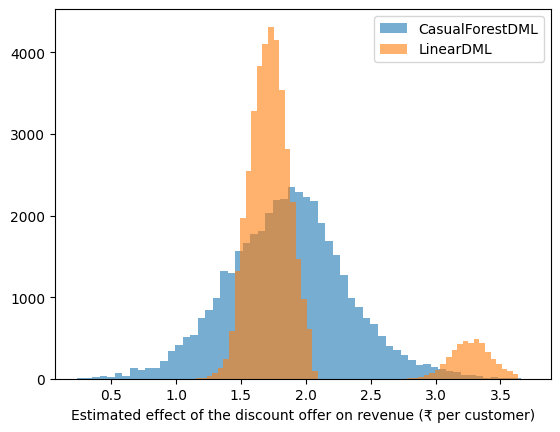

In [13]:
plt.hist(ite_forest,bins=60,alpha=.6,label='CasualForestDML')
plt.hist(ite_lin,bins=60,alpha=.6,label='LinearDML')
plt.xlabel('Estimated effect of the discount offer on revenue (₹ per customer)'); plt.legend(); plt.show()

In [14]:
scores = save_ite_scores(df, ite_forest, '../data/ite_scores.csv')
scores.head()

,customer_id,ite,recency,history,is_referral
0,2,1.680934,6,329.08,1
1,4,1.678784,9,675.83,1
2,9,1.855862,9,675.07,1
3,14,1.961688,2,101.64,0
4,15,1.753763,4,241.42,1
